# Part A 补充：缺失值填补方法对比

本 notebook 比较几种缺失值处理方法，看哪种最适合 `q1.csv`。

**比较的方法**

| 简称 | 方法 | 一句话解释 |
|---|---|---|
| `median` | 中位数填补 | 缺了就填这一列的中位数 |
| `interp` | 时间插值 | 用同一传感器**前后时刻**的读数连直线来填（假设行按时间排序） |
| `knn` | K 近邻填补 | 用**其他传感器**找出最相似的 5 行，取它们**这一列**的加权平均 |
| `mice_lin` | 迭代式模型填补（线性回归） | 把每个有缺失的列当作目标，用其他列做线性回归来预测，轮流迭代 |
| `mice_rf` | 迭代式模型填补（随机森林） | 同上，但回归模型换成更灵活的随机森林 |
| `hybrid` | 混合 | 整套传感器都缺 → 时间插值；只缺个别列 → KNN |
| `drop` | 删除 | 直接删掉有缺失的行（只在实验 3 中比较） |

**三个实验**

1. **只缺 NOx(GT)/NO2(GT)**：从完整数据里随机遮住一些值，再填回去，看误差。
2. **整套传感器连续缺失一段时间**：模拟设备停机，遮住连续几小时的整套传感器读数，看误差随缺口长度如何变化。
3. **对最终预测的影响**：用每种方法处理真实数据，再用线性回归预测 CO，比较交叉验证误差。

误差统一用 **"标准化 MAE"** 表示 = 平均绝对误差 ÷ 该列标准差。
0 = 完美；约 0.8 ≈ 跟直接填中位数差不多（等于没用上任何信息）。

In [3]:
%pip install numpy pandas matplotlib scikit-learn

  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl (5.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 19.0 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 17.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 16.2 MB/s  0:00:00 eta 0:00:01
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 17.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.2 MB/s  0:00:00 eta 0:00:01
Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl (20.3 MB)
   ━━━━━━━━━━

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (必须先导入才能用 IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

df = pd.read_csv("q1.csv")          # 如路径不同请修改
TARGET = "CO(GT)"
FEATURES = [c for c in df.columns if c != TARGET]

# "整套传感器"：设备停机时这 9 列总是一起缺
SENSOR_BLOCK = ["PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "PT08.S3(NOx)",
                "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]
REF_COLS = ["NOx(GT)", "NO2(GT)"]

print("数据形状:", df.shape)
df.head()

数据形状: (7674, 12)


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 0. 缺失情况概览

In [3]:
miss_pct = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
print("每列缺失百分比 (%):")
print(miss_pct.to_string())

pattern = df[FEATURES].isna().apply(
    lambda r: ", ".join(r.index[r]) if r.any() else "(no missing)", axis=1)
print("\n缺失模式（哪些列同时缺失）:")
print(pattern.value_counts().to_string())

# 整套传感器缺失时，缺口有多长（连续多少行）？
m = df["PT08.S1(CO)"].isna().astype(int)
runs = m.groupby((m.diff() != 0).cumsum()).agg(["first", "size"])
gap_lengths = runs.loc[runs["first"] == 1, "size"]
print("\n整套传感器缺失的缺口长度（行数）:", sorted(gap_lengths.tolist()))

每列缺失百分比 (%):
NO2(GT)          5.42
NOx(GT)          5.38
PT08.S1(CO)      4.30
C6H6(GT)         4.30
PT08.S2(NMHC)    4.30
PT08.S3(NOx)     4.30
PT08.S4(NO2)     4.30
PT08.S5(O3)      4.30
T                4.30
RH               4.30
AH               4.30
CO(GT)           0.00

缺失模式（哪些列同时缺失）:
(no missing)                                                                                                  6941
NOx(GT), NO2(GT)                                                                                               400
PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), PT08.S3(NOx), PT08.S4(NO2), PT08.S5(O3), T, RH, AH                       317
PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), NOx(GT), PT08.S3(NOx), NO2(GT), PT08.S4(NO2), PT08.S5(O3), T, RH, AH      13
NO2(GT)                                                                                                          3

整套传感器缺失的缺口长度（行数）: [1, 1, 1, 3, 4, 5, 9, 24, 37, 45, 51, 74, 75]


## 1. 定义各填补方法

每个函数输入一张**只含特征列**（不含目标 CO）的表，返回填好的表。

- 不把目标 CO(GT) 放进填补过程，避免"答案"泄露进特征。
- KNN 和 MICE 先**标准化**（把各列调到同一尺度），否则数值大的列（如 NOx 可达 1000+）会主导"距离"或回归。

In [10]:
def _scaled_impute(X, imputer):
    # 先标准化 → 填补 → 还原到原始单位
    scaler = StandardScaler()
    Z = scaler.fit_transform(X)              # StandardScaler 会忽略 NaN 计算均值/标准差
    Z_filled = imputer.fit_transform(Z)
    return pd.DataFrame(scaler.inverse_transform(Z_filled), columns=X.columns, index=X.index)


def impute_median(X):
    return pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X),
                        columns=X.columns, index=X.index)


def impute_interp(X):
    # 时间插值：前提是行按时间顺序排列
    return X.interpolate(method="linear", limit_direction="both")


def impute_knn(X, k=5):
    return _scaled_impute(X, KNNImputer(n_neighbors=k, weights="distance"))


def impute_mice_lin(X):
    return _scaled_impute(X, IterativeImputer(max_iter=10, random_state=0))


def impute_mice_rf(X):
    rf = RandomForestRegressor(n_estimators=20, max_depth=12, n_jobs=-1, random_state=0)
    return _scaled_impute(X, IterativeImputer(estimator=rf, max_iter=3, random_state=0))


def impute_hybrid(X):
    # 整套传感器都缺的行 → 只用时间插值填这 9 列；其余缺失 → KNN
    X = X.copy()
    block_rows = X[SENSOR_BLOCK].isna().all(axis=1)
    interp = X.interpolate(method="linear", limit_direction="both")
    X.loc[block_rows, SENSOR_BLOCK] = interp.loc[block_rows, SENSOR_BLOCK]
    return impute_knn(X)


METHODS = {
    "median":   impute_median,
    "interp":   impute_interp,
    "knn":      impute_knn,
    "mice_lin": impute_mice_lin,
    "mice_rf":  impute_mice_rf,
}

## 2. 实验 1：只缺 NOx(GT) / NO2(GT)

做法：取**没有任何缺失**的行（真实值已知），随机遮住 10% 的 NOx(GT) 和 NO2(GT)，用各方法填回去，再和真实值比较。重复 5 次（不同随机种子）取平均。

> 这对应真实数据中 "只缺参考仪器读数" 的 400 多行。

In [11]:
full = df[FEATURES].dropna().reset_index(drop=True)   # 完整行，保持原有时间顺序
col_std = full.std()

def norm_mae(pred, truth, cols):
    # 标准化 MAE：每列 MAE ÷ 该列标准差
    return ((pred[cols] - truth[cols]).abs().mean() / col_std[cols])

results1 = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    masked = full.copy()
    for col in REF_COLS:
        idx = rng.choice(len(full), size=len(full) // 10, replace=False)
        masked.loc[idx, col] = np.nan
    for name, fn in METHODS.items():
        filled = fn(masked)
        for col in REF_COLS:
            hidden = masked[col].isna() & full[col].notna()
            err = (filled.loc[hidden, col] - full.loc[hidden, col]).abs().mean() / col_std[col]
            results1.append({"seed": seed, "method": name, "column": col, "norm_MAE": err})

res1 = (pd.DataFrame(results1)
        .groupby(["method", "column"])["norm_MAE"].mean()
        .unstack().round(3))
res1["average"] = res1.mean(axis=1).round(3)
res1 = res1.sort_values("average")
res1

column,NO2(GT),NOx(GT),average
method,,,
knn,0.252,0.144,0.198
mice_rf,0.246,0.158,0.202
interp,0.225,0.196,0.211
mice_lin,0.352,0.258,0.305
median,0.782,0.699,0.740


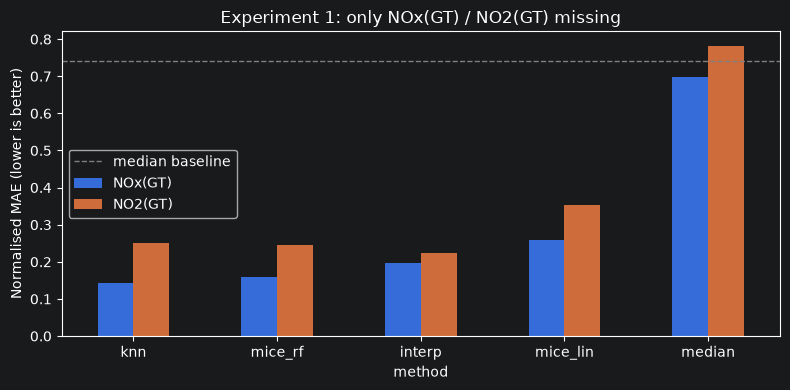

In [12]:
ax = res1[REF_COLS].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("Normalised MAE (lower is better)")
ax.set_title("Experiment 1: only NOx(GT) / NO2(GT) missing")
ax.axhline(res1.loc["median", "average"], ls="--", c="grey", lw=1, label="median baseline")
ax.legend()
plt.tight_layout()
plt.show()

## 3. 实验 2：整套传感器连续缺失（模拟设备停机）

做法：在完整数据里，随机放 15 个**互不重叠**的缺口，每个缺口内把 9 个传感器列**全部**遮住（只留下 NOx(GT)/NO2(GT)，和真实情况一样）。缺口长度从 1 小时到 48 小时，每种长度重复 3 次。

> 这对应真实数据中 "整套传感器一起缺" 的 330 行。
> 注意：此时 KNN / MICE 只能靠 NOx(GT) 和 NO2(GT) 两列来推断另外 9 列。

In [17]:
GAP_LENGTHS = [1, 3, 6, 12, 24, 48]
N_GAPS = 15
N_REPEATS = 3

def random_gaps(n_rows, gap_len, n_gaps, rng):
    # 随机放置互不重叠的缺口，返回被遮住的行号
    starts = []
    while len(starts) < n_gaps:
        s = int(rng.integers(1, n_rows - gap_len - 1))
        if all(abs(s - t) > gap_len + 1 for t in starts):
            starts.append(s)
    return np.concatenate([np.arange(s, s + gap_len) for s in starts])

results2 = []
t0 = time.time()
for L in GAP_LENGTHS:
    for rep in range(N_REPEATS):
        rng = np.random.default_rng(100 * L + rep)
        rows = random_gaps(len(full), L, N_GAPS, rng)
        masked = full.copy()
        masked.loc[rows, SENSOR_BLOCK] = np.nan
        for name, fn in METHODS.items():
            filled = fn(masked)
            err = ((filled.loc[rows, SENSOR_BLOCK] - full.loc[rows, SENSOR_BLOCK]).abs().mean()
                   / col_std[SENSOR_BLOCK]).mean()
            results2.append({"gap_len": L, "method": name, "norm_MAE": err})
print(f"耗时 {time.time() - t0:.0f} 秒")

res2 = (pd.DataFrame(results2)
        .groupby(["method", "gap_len"])["norm_MAE"].mean()
        .unstack().round(3))
res2

耗时 41 秒


gap_len,1,3,6,12,24,48
method,,,,,,
interp,0.176,0.217,0.371,0.573,0.643,0.684
knn,0.747,0.584,0.730,0.604,0.634,0.647
median,0.797,0.762,0.863,0.789,0.834,0.776
mice_lin,0.672,0.631,0.767,0.654,0.669,0.628
mice_rf,0.759,0.731,0.849,0.749,0.793,0.748


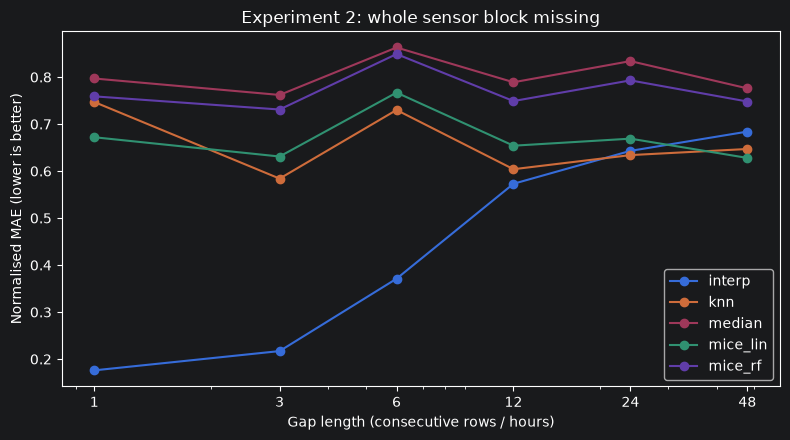

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in res2.index:
    ax.plot(res2.columns, res2.loc[name], marker="o", label=name)
ax.set_xscale("log")
ax.set_xticks(GAP_LENGTHS)
ax.set_xticklabels(GAP_LENGTHS)
ax.set_xlabel("Gap length (consecutive rows / hours)")
ax.set_ylabel("Normalised MAE (lower is better)")
ax.set_title("Experiment 2: whole sensor block missing")
ax.legend()
plt.tight_layout()
plt.show()

## 4. 实验 3：对最终预测 CO 的影响

前两个实验看的是"填得准不准"，这个实验看"对最终任务有没有帮助"。

做法：
1. 用每种方法处理**真实的**缺失数据；
2. 用线性回归预测 CO(GT)，做 5 折交叉验证（把数据分成 5 份，轮流拿 1 份当测试、4 份训练）；
3. **只在原本就完整的行上计算误差**，这样每种方法都在同一批测试行上被评估，比较才公平；
4. `drop_block` = 第一题的方案（删掉整套传感器缺失的行 + KNN）；`drop_all` = 删掉所有有缺失的行。

> 说明：为了简洁，填补在切分之前对整份数据做（填补时没有用到目标 CO，所以泄露很小）。正式做 C 题时应只在训练集上学习填补规则。

In [15]:
X_raw = df[FEATURES]
y = df[TARGET].values
complete = X_raw.notna().all(axis=1).values          # 原本就完整的行
block_rows = X_raw[SENSOR_BLOCK].isna().all(axis=1).values

datasets = {name: (fn(X_raw), np.ones(len(df), bool)) for name, fn in METHODS.items()}
datasets["hybrid"]     = (impute_hybrid(X_raw), np.ones(len(df), bool))
datasets["drop_block"] = (impute_knn(X_raw.loc[~block_rows]).reindex(X_raw.index), ~block_rows)
datasets["drop_all"]   = (X_raw, complete)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, (X_filled, usable) in datasets.items():
    rmses = []
    for tr, te in kf.split(X_raw):
        tr = tr[usable[tr]]                          # 训练只用该方法保留下来的行
        te = te[complete[te]]                        # 测试统一用原本完整的行
        model = LinearRegression().fit(X_filled.values[tr], y[tr])
        pred = model.predict(X_filled.values[te])
        rmses.append(np.sqrt(np.mean((pred - y[te]) ** 2)))
    rows.append({"method": name, "train_rows_used": int(usable.sum()),
                 "CV_RMSE_mean": np.mean(rmses), "CV_RMSE_std": np.std(rmses)})

res3 = pd.DataFrame(rows).set_index("method").sort_values("CV_RMSE_mean").round(4)
res3

,train_rows_used,CV_RMSE_mean,CV_RMSE_std
method,,,
drop_block,7344,0.4334,0.0164
drop_all,6941,0.4334,0.0166
knn,7674,0.4336,0.0159
mice_lin,7674,0.4349,0.0166
interp,7674,0.4403,0.0153
hybrid,7674,0.4420,0.0152
median,7674,0.4449,0.0159
mice_rf,7674,0.4497,0.0167


## 5. 汇总

In [16]:
summary = pd.DataFrame({
    "Exp1: NOx/NO2 missing (avg)": res1["average"],
    "Exp2: block gap = 1h":  res2[1],
    "Exp2: block gap = 3h":  res2[3],
    "Exp2: block gap = 24h": res2[24],
}).round(3)
summary["Exp3: CV RMSE"] = res3["CV_RMSE_mean"]
summary.sort_values("Exp1: NOx/NO2 missing (avg)")

,Exp1: NOx/NO2 missing (avg),Exp2: block gap = 1h,Exp2: block gap = 3h,Exp2: block gap = 24h,Exp3: CV RMSE
method,,,,,
knn,0.198,0.747,0.584,0.634,0.4336
mice_rf,0.202,0.759,0.731,0.793,0.4497
interp,0.211,0.176,0.217,0.643,0.4403
mice_lin,0.305,0.672,0.631,0.669,0.4349
median,0.740,0.797,0.762,0.834,0.4449


## 6. 结论（请根据你跑出的数字核对后再写进报告）

**实验 1（只缺 NOx/NO2）**：KNN 和时间插值最好，误差约为中位数填补的 1/3 到 1/4；MICE（随机森林）次之，MICE（线性）较弱。原因是 NOx/NO2 与几个便宜传感器关系紧密但不完全是直线关系，KNN 能捕捉到这一点，线性模型不能。

**实验 2（整套传感器缺失）**：时间插值在短缺口（≤ 3 小时）时明显最好；缺口越长，所有方法都越接近"瞎猜"。KNN/MICE 只能靠两列 NOx/NO2 推断九列，效果有限。

**实验 3（对预测的影响）**：各方法的最终 RMSE 差别通常很小，因为缺失只占约 10%，而且是在同一批完整行上评估的。也就是说，**选哪种方法对最终模型影响不大，关键是理由讲清楚**。

**推荐**：
- 只缺个别列 → **KNN**（利用传感器之间的关系）；
- 整套传感器都缺 → 短缺口用**时间插值**，长缺口**删除**（插值误差已接近随机）；
- 报告中写明时间插值的前提：行按时间顺序排列（数据无时间戳，由缺失连续出现推断）。